In [29]:
import pymc as pm
import arviz as az
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import log_loss, roc_auc_score
import numpy as np

In [7]:
splits = {'train': 'data/train-00000-of-00001.parquet', 'validation': 'data/validation-00000-of-00001.parquet', 'test': 'data/test-00000-of-00001.parquet'}
train_df = pd.read_parquet("hf://datasets/FelixCS3/statsbomb-open-data-shots/" + splits["train"])
validation_df = pd.read_parquet("hf://datasets/FelixCS3/statsbomb-open-data-shots/" + splits["validation"])
test_df = pd.read_parquet("hf://datasets/FelixCS3/statsbomb-open-data-shots/" + splits["test"])

In [8]:
## Preprocessing
## Continuous feature is distance_to_goal
## Discrete features are under_pressure, shot_technique_name, shot_type_name

continuous_cols = ['distance_to_goal', 'angle_to_goal']
discrete_cols = ['under_pressure', 'is_goal']
categorical_cols = ['shot_technique_name', 'shot_type_name']

## under_pressure column already boolean
train_df["under_pressure"] = train_df["under_pressure"].astype(float)
validation_df["under_pressure"] = validation_df["under_pressure"].astype(float)
test_df["under_pressure"] = test_df["under_pressure"].astype(float)


preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', StandardScaler(), continuous_cols),
        ('discrete', 'passthrough', discrete_cols),
        ('categorical', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ]
)

preprocessor.set_output(transform="pandas")
df = preprocessor.fit_transform(train_df)
df

,continuous__distance_to_goal,continuous__angle_to_goal,discrete__under_pressure,discrete__is_goal,categorical__shot_technique_name_Backheel,categorical__shot_technique_name_Diving Header,categorical__shot_technique_name_Half Volley,categorical__shot_technique_name_Lob,categorical__shot_technique_name_Normal,categorical__shot_technique_name_Overhead Kick,categorical__shot_technique_name_Volley,categorical__shot_type_name_Corner,categorical__shot_type_name_Free Kick,categorical__shot_type_name_Open Play,categorical__shot_type_name_Penalty
0,-1.389727,-0.017919,0.0,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.513920,0.493088,0.0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.047995,0.075318,0.0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.827265,-1.442656,0.0,1,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.784327,-1.398003,0.0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70421,-1.055398,0.835487,1.0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
70422,1.470789,-0.699487,0.0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
70423,0.727221,-1.396627,1.0,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
70424,-0.739700,0.803458,0.0,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [9]:
val_df = preprocessor.transform(validation_df)
test_df = preprocessor.transform(test_df)

In [ ]:
## Bayesian Logistic Regression with Weakly Informative Priors

with pm.Model() as model:
    # Priors for coefficients
    intercept = pm.Normal("Intercept", mu=0, sigma=1)
    w_distance     = pm.Normal("w_distance", mu=0, sigma=1)
    w_angle = pm.Normal("w_angle", mu=0, sigma=1)
    w_pressure = pm.Normal("w_pressure", mu=0, sigma=1)
    # w_backheel    = pm.Normal("w_backheel", mu=0, sigma=1)
    # w_diving_header = pm.Normal("w_diving_header", mu=0, sigma=1)
    # w_half_volley = pm.Normal("w_half_volley", mu=0, sigma=1)
    # w_lob = pm.Normal("w_lob", mu=0, sigma=1)
    # w_normal = pm.Normal("w_normal", mu=0, sigma=1)
    # w_overhead_kick = pm.Normal("w_overhead", mu=0, sigma=1)
    # w_volley = pm.Normal("w_volley", mu=0, sigma=1)
    w_corner = pm.Normal("w_corner", mu=0, sigma=1)
    w_free_kick = pm.Normal("w_free_kick", mu=0, sigma=1)
    w_open_play = pm.Normal("w_open_play", mu=0, sigma=1)
    w_penalty = pm.Normal("w_penalty", mu=0, sigma=1)

    # Linear predictor and logit link function
    logit_p = (
        intercept
        + w_distance      * df["continuous__distance_to_goal"]
        + w_angle * df["continuous__angle_to_goal"]
        + w_pressure      * df["discrete__under_pressure"]
        # + w_backheel      * df["categorical__shot_technique_name_Backheel"]
        # + w_diving_header * df["categorical__shot_technique_name_Diving Header"]
        # + w_half_volley   * df["categorical__shot_technique_name_Half Volley"]
        # + w_lob           * df["categorical__shot_technique_name_Lob"]
        # + w_normal        * df["categorical__shot_technique_name_Normal"]
        # + w_overhead_kick * df["categorical__shot_technique_name_Overhead Kick"]
        # + w_volley        * df["categorical__shot_technique_name_Volley"]
        + w_corner        * df["categorical__shot_type_name_Corner"]
        + w_free_kick     * df["categorical__shot_type_name_Free Kick"]
        + w_open_play     * df["categorical__shot_type_name_Open Play"]
        + w_penalty       * df["categorical__shot_type_name_Penalty"]
    )
    # p = pm.Deterministic("p", pm.math.sigmoid(logit_p))
    p = pm.math.sigmoid(logit_p)

    # Likelihood: 'is_goal' is a binary variable (Bernoulli)
    is_evolved_obs = pm.Bernoulli("is_evolved_obs", p=p, observed=df["discrete__is_goal"])

    # Sample from the posterior
    trace_logit = pm.sample(draws=10000, tune=1800, chains=4, step=pm.Metropolis(), progressbar=True, idata_kwargs={"log_likelihood": False})

# Get overall summary and trace plots
print(az.summary(trace_logit, round_to=2))

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [Intercept]
>Metropolis: [w_distance]
>Metropolis: [w_angle]
>Metropolis: [w_pressure]
>Metropolis: [w_corner]
>Metropolis: [w_free_kick]
>Metropolis: [w_open_play]
>Metropolis: [w_penalty]


Output()

/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),
/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),
/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


... (2 outputs left out)

/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),
/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),
/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_800 tune and 10_000 draw iterations (7_200 + 40_000 draws total) took 764 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


             mean    sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  \
Intercept   -1.07  0.29     -1.64     -0.68      7.06     10.60   1.55   
w_distance  -1.18  0.02     -1.21     -1.15   2507.33   3109.99   1.00   
w_angle     -0.11  0.01     -0.13     -0.09   5658.14   5497.84   1.00   
w_pressure  -0.59  0.03     -0.65     -0.54   3548.48   4557.24   1.00   
w_corner     2.99  0.52      2.16      3.82     37.25     66.89   1.07   
w_free_kick -0.45  0.29     -0.85      0.11      7.47     10.32   1.50   
w_open_play -1.41  0.29     -1.80     -0.84      7.06     10.36   1.55   
w_penalty    0.94  0.29      0.54      1.51      7.45     10.38   1.50   

             mcse_mean  mcse_sd  
Intercept         0.11     0.06  
w_distance        0.00     0.00  
w_angle           0.00     0.00  
w_pressure        0.00     0.00  
w_corner          0.08     0.01  
w_free_kick       0.11     0.06  
w_open_play       0.11     0.06  
w_penalty         0.11     0.06  


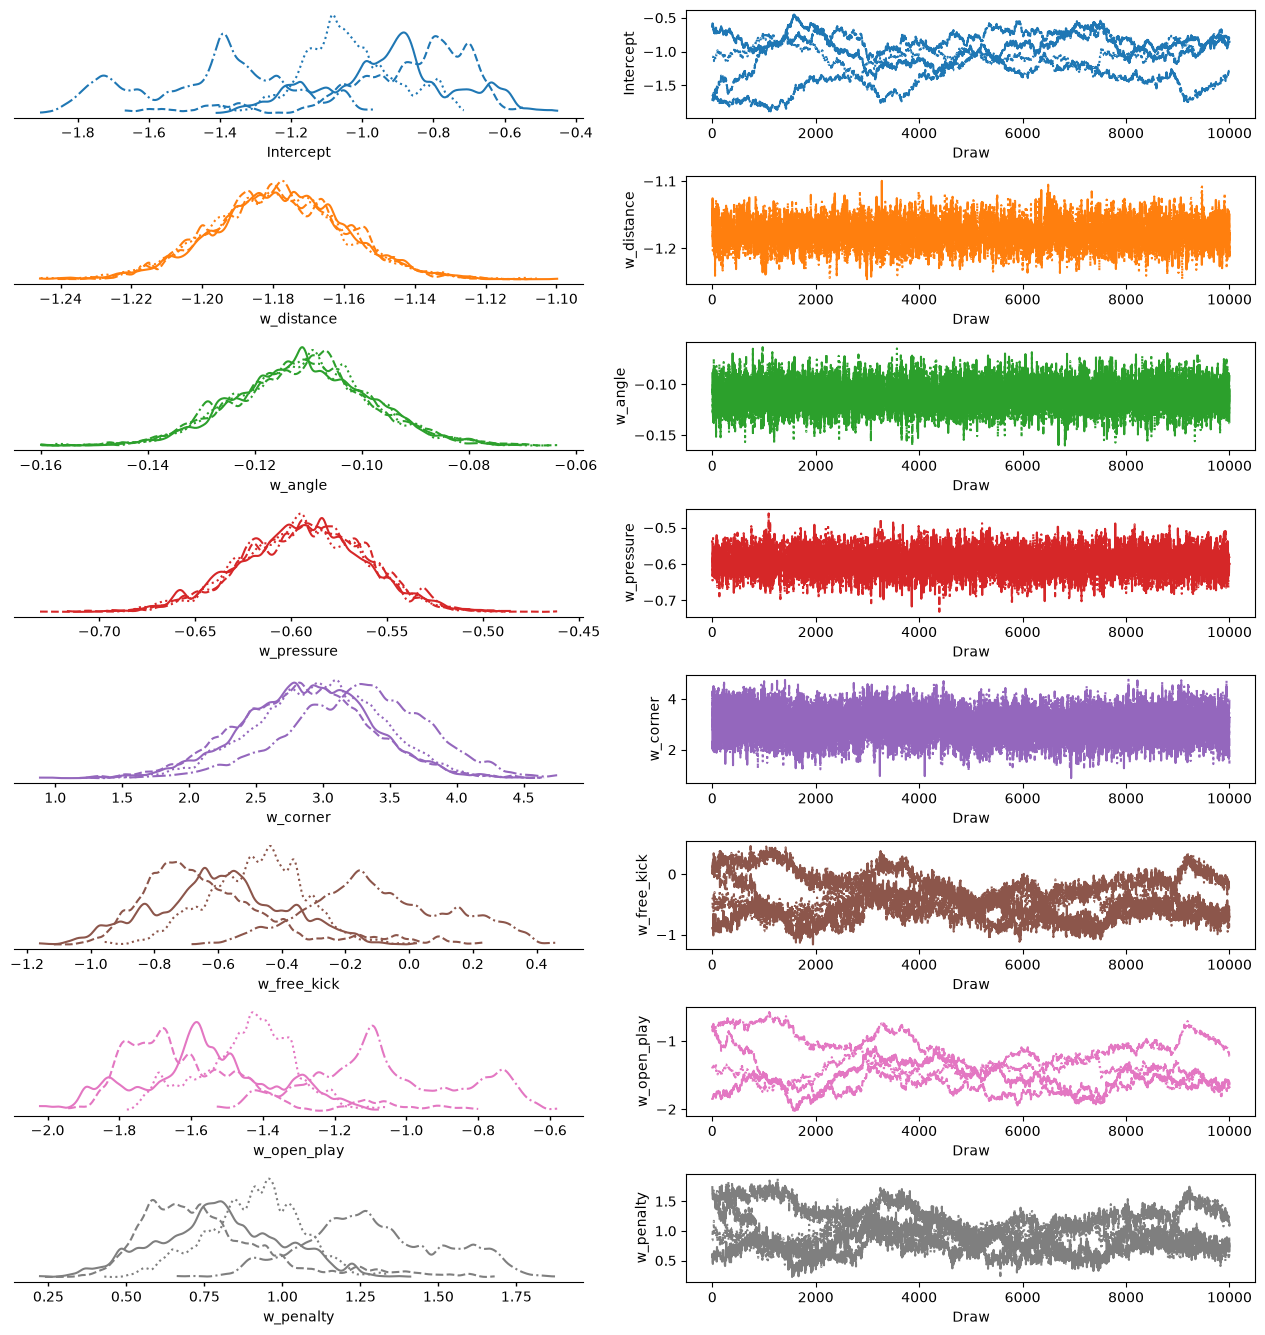

In [11]:
az.plot_trace_dist(trace_logit)
plt.tight_layout()

In [12]:
## Bayesian Logistic Regression with Weakly Informative Priors

## shot_type_name weights showed poor mixing/high autocorrelation, trying now with just distance_to_goal, angle_to_goal, under_pressure

with pm.Model() as model:
    # Priors for coefficients
    intercept = pm.Normal("Intercept", mu=0, sigma=1)
    w_distance     = pm.Normal("w_distance", mu=0, sigma=1)
    w_angle = pm.Normal("w_angle", mu=0, sigma=1)
    w_pressure = pm.Normal("w_pressure", mu=0, sigma=1)

    # Linear predictor and logit link function
    logit_p = (
        intercept
        + w_distance      * df["continuous__distance_to_goal"]
        + w_angle * df["continuous__angle_to_goal"]
        + w_pressure      * df["discrete__under_pressure"]
    )
    # p = pm.Deterministic("p", pm.math.sigmoid(logit_p))
    p = pm.math.sigmoid(logit_p)

    # Likelihood: 'is_goal' is a binary variable (Bernoulli)
    is_evolved_obs = pm.Bernoulli("is_evolved_obs", p=p, observed=df["discrete__is_goal"])

    # Sample from the posterior
    trace_logit = pm.sample(draws=10000, tune=1800, chains=4, step=pm.Metropolis(), progressbar=True, idata_kwargs={"log_likelihood": False})

# Get overall summary and trace plots
print(az.summary(trace_logit, round_to=2))

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [Intercept]
>Metropolis: [w_distance]
>Metropolis: [w_angle]
>Metropolis: [w_pressure]


Output()

/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),
/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),
/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),
/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),
/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),
/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_800 tune and 10_000 draw iterations (7_200 + 40_000 draws total) took 364 seconds.


            mean    sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  \
Intercept  -2.33  0.02     -2.35     -2.30   2509.26   3525.50    1.0   
w_distance -1.17  0.02     -1.20     -1.14   2511.72   3610.68    1.0   
w_angle    -0.24  0.01     -0.26     -0.22   5477.90   5177.78    1.0   
w_pressure -0.75  0.03     -0.80     -0.70   4934.48   5697.27    1.0   

            mcse_mean  mcse_sd  
Intercept         0.0      0.0  
w_distance        0.0      0.0  
w_angle           0.0      0.0  
w_pressure        0.0      0.0  


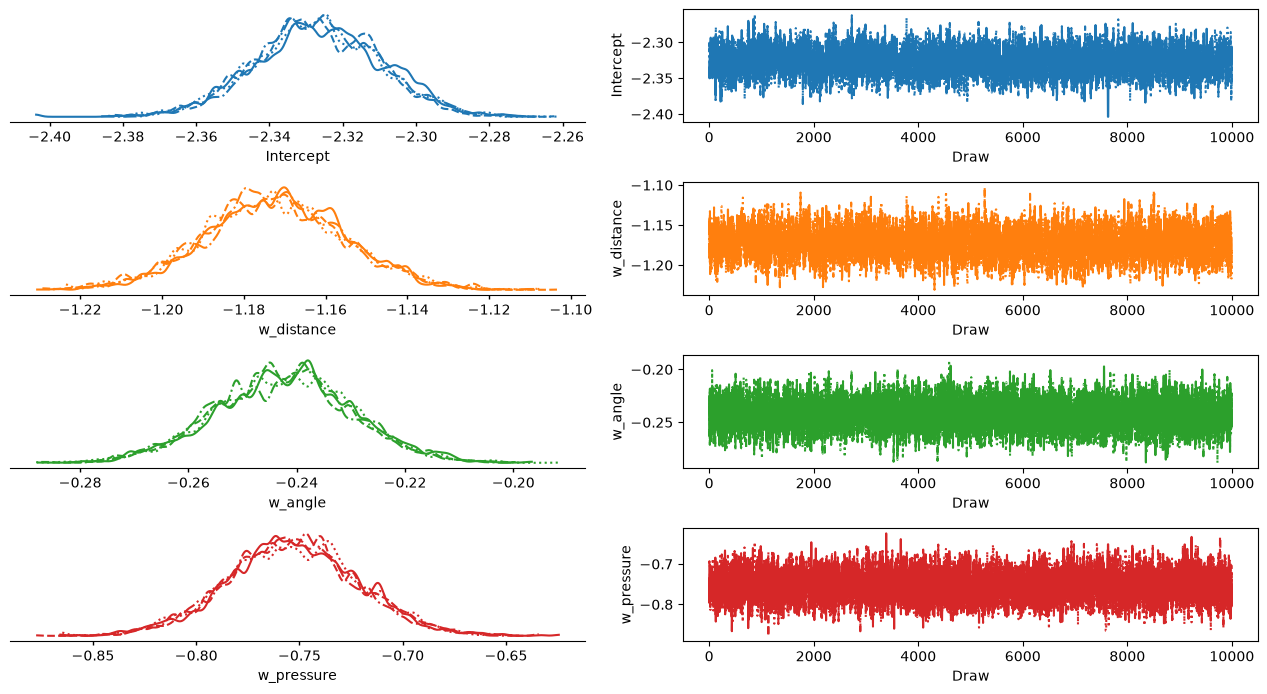

In [13]:
az.plot_trace_dist(trace_logit)
plt.tight_layout()

In [16]:
## Bayesian Logistic Regression with Informative Priors

with pm.Model() as model:
    # Priors for coefficients
    intercept = pm.Normal("Intercept", mu=np.log(.1), sigma=0.1)   ## roughly 10% of all shots result in a goal
    w_distance     = pm.Normal("w_distance", mu=np.log(0.8), sigma=0.5)   ## distance std dev was about 9 yards, guess that increasing distance by 9 yards results in a 20% decrease in goal chance
    w_angle = pm.Normal("w_angle", mu=np.log(0.9), sigma=0.5)  ## angle std dev was about 18 deg, guess that increasing shot angle by 18 deg results in 10% decrease in goal chance
    w_pressure = pm.Normal("w_pressure", mu=np.log(0.8), sigma=0.5) ## guess that being under pressure results in 20% decrease in goal chance

    # Linear predictor and logit link function
    logit_p = (
        intercept
        + w_distance      * df["continuous__distance_to_goal"]
        + w_angle * df["continuous__angle_to_goal"]
        + w_pressure      * df["discrete__under_pressure"]
    )
    # p = pm.Deterministic("p", pm.math.sigmoid(logit_p))
    p = pm.math.sigmoid(logit_p)

    # Likelihood: 'is_goal' is a binary variable (Bernoulli)
    is_evolved_obs = pm.Bernoulli("is_evolved_obs", p=p, observed=df["discrete__is_goal"])

    # Sample from the posterior
    trace_logit = pm.sample(draws=10000, tune=1800, chains=4, step=pm.Metropolis(), progressbar=True, idata_kwargs={"log_likelihood": False})

# Get overall summary and trace plots
print(az.summary(trace_logit, round_to=2))

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [Intercept]
>Metropolis: [w_distance]
>Metropolis: [w_angle]
>Metropolis: [w_pressure]


Output()

/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/step_methods/metropolis.py:322: RuntimeWarning: overflow encountered in exp
  "accept": np.mean(np.exp(self.accept_rate_iter)),


/home/joeya/.cache/pypoetry/virtualenvs/expected-goals-bayesian-mlp-wLusil5v-py3.12/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1185: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 4 chains for 1_800 tune and 10_000 draw iterations (7_200 + 40_000 draws total) took 378 seconds.


            mean    sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  \
Intercept  -2.33  0.02     -2.35     -2.30   2407.43   3513.11    1.0   
w_distance -1.17  0.02     -1.20     -1.14   2687.22   3785.96    1.0   
w_angle    -0.24  0.01     -0.26     -0.22   6560.50   6266.88    1.0   
w_pressure -0.75  0.03     -0.80     -0.70   4371.58   4449.63    1.0   

            mcse_mean  mcse_sd  
Intercept         0.0      0.0  
w_distance        0.0      0.0  
w_angle           0.0      0.0  
w_pressure        0.0      0.0  


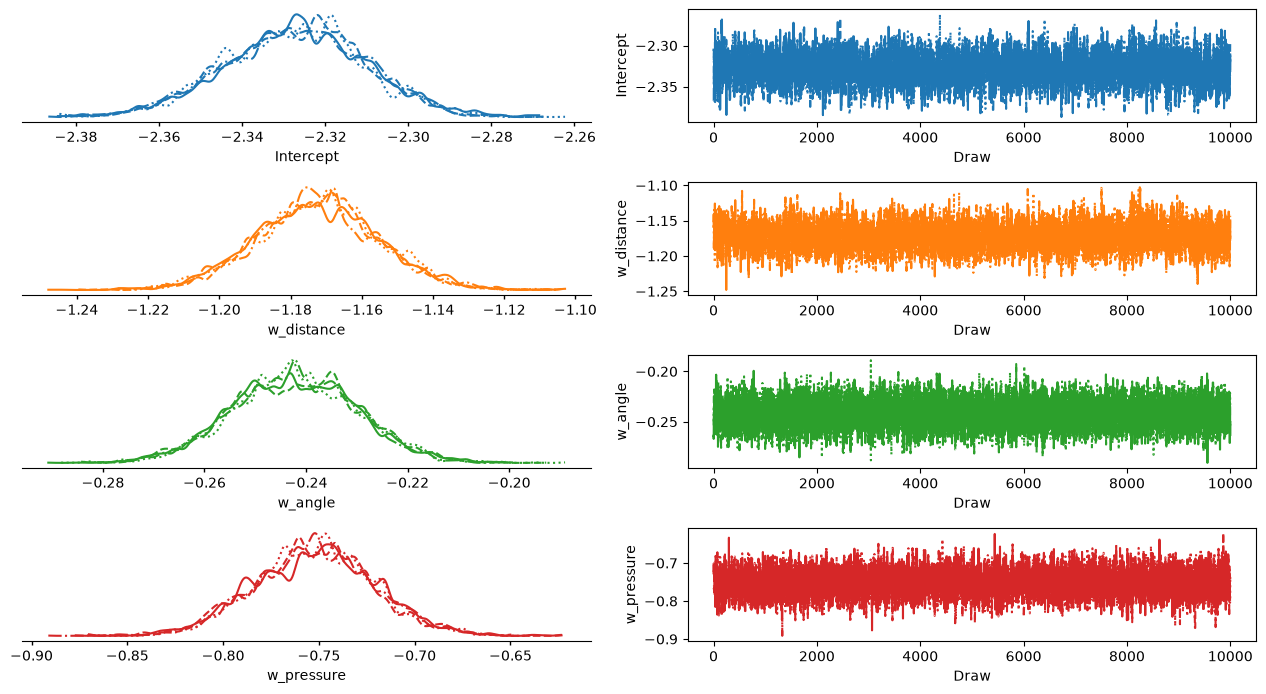

In [17]:
az.plot_trace_dist(trace_logit)
plt.tight_layout()

In [28]:
## Evaluate on test set using cross entropy loss and posterior means

## get posterior means
intercept = trace_logit.posterior["Intercept"].mean().item()
w_distance = trace_logit.posterior["w_distance"].mean().item()
w_angle = trace_logit.posterior["w_angle"].mean().item()
w_pressure = trace_logit.posterior["w_pressure"].mean().item()

logit_p = (
    intercept
    + w_distance * test_df["continuous__distance_to_goal"]
    + w_angle    * test_df["continuous__angle_to_goal"]
    + w_pressure * test_df["discrete__under_pressure"]
)
p_pred = 1 / (1 + np.exp(-logit_p))

print(f"Test log loss: {log_loss(test_df["discrete__is_goal"], p_pred)}")
print(f"Log loss of predicting 0.1 for every shot: {log_loss(test_df["discrete__is_goal"], np.full((len(test_df), 1), 0.1))}")

original_test_df = pd.read_parquet("hf://datasets/FelixCS3/statsbomb-open-data-shots/" + splits["test"])
print(f"Log loss of official StatsBomb prediction: {log_loss(test_df["discrete__is_goal"], original_test_df["xg_statsbomb"])}")

Test log loss: 0.3073255767550629
Log loss of predicting 0.1 for every shot: 0.3497184460465755
Log loss of official StatsBomb prediction: 0.27142962996735476


In [32]:
print(f"Test AUROC: {roc_auc_score(test_df["discrete__is_goal"], p_pred)}")
print(f"AUROC of predicting no goal for every shot: {roc_auc_score(test_df["discrete__is_goal"], np.full((len(test_df), 1), 0.1))}")
print(f"AUROC of official StatsBomb prediction: {roc_auc_score(test_df["discrete__is_goal"], original_test_df["xg_statsbomb"])}")

Test AUROC: 0.7517495472405171
AUROC of predicting no goal for every shot: 0.5
AUROC of official StatsBomb prediction: 0.8132181747160724
